In [1]:
from src.gaussian_mixture import GaussianMixtureMAR
from src.data_generator import DataGenerator
from src.missingness_generator import MissingnessGenerator
from src.utils import true_quantile

import numpy as np
import matplotlib.pyplot as plt
import torch

from src.metrics import energy_distance

from joblib import Parallel, delayed

In [2]:
kk = (1,20)

In [3]:
def example2_logistic(n=2000):
    U = torch.rand(n, 2)
    X = torch.special.logit(U)
    mg = MissingnessGenerator(U)
    M = mg.example2(U[:,0], U[:, 1])
    Xtest = torch.special.logit(torch.rand(n, 2))
    gmm = GaussianMixtureMAR(kk)
    gmm.fit(X, M)
    Xtilde = gmm.sample(n)[0]
    ed = energy_distance(Xtest, Xtilde).item()
    ds = gmm.evaluate(Xtest).item()
    return ed, ds

In [4]:
n = 2000
U = torch.rand(n, 2)
X = torch.special.logit(U)
mg = MissingnessGenerator(U)
M = mg.example2(U[:,0], U[:, 1])
Xtest = torch.special.logit(torch.rand(n, 2))
gmm = GaussianMixtureMAR(kk)
gmm.fit(X, M)
Xtilde = gmm.sample(n)[0]

In [5]:
# Standard logistic PDF
x = np.linspace(-4, 4, 500)
pdf = np.exp(-x) / (1 + np.exp(-x))**2

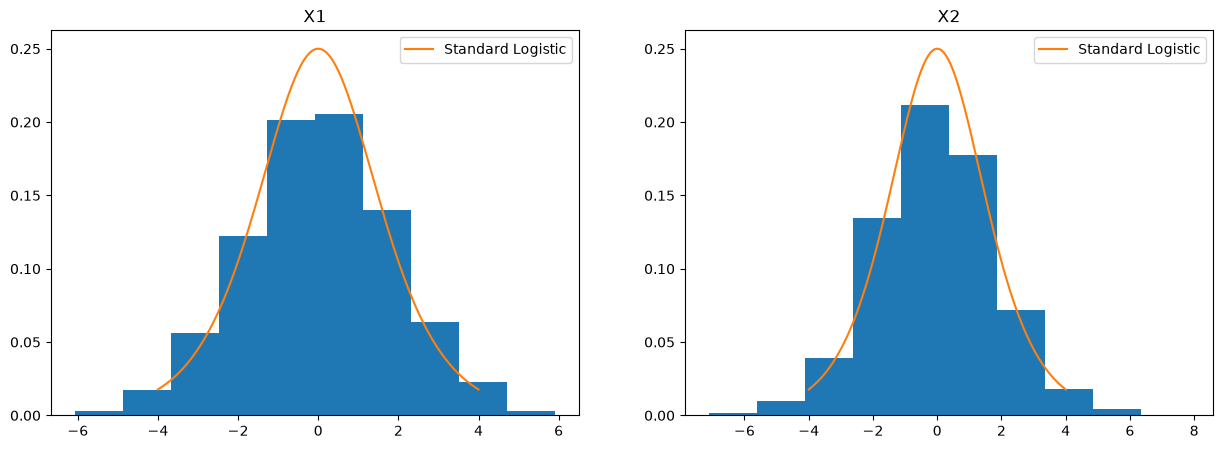

In [6]:
_, axes = plt.subplots(1, 2, figsize=(15,5))

axes[0].hist(Xtilde[:,0], density=True)
axes[0].plot(x, pdf, label="Standard Logistic")
axes[0].legend()
axes[0].set_title('X1')

axes[1].hist(Xtilde[:,1], density=True)
axes[1].plot(x, pdf, label="Standard Logistic")
axes[1].legend()
axes[1].set_title('X2')

plt.show()

In [7]:
def example2_normal(n=2000):
    U = torch.rand(n, 2)
    X = torch.distributions.Normal(0, 1).icdf(U)
    mg = MissingnessGenerator(U)
    M = mg.example2(U[:,0], U[:, 1])
    Xtest = torch.randn(n, 2) # N2(0,1)
    gmm = GaussianMixtureMAR(kk)
    gmm.fit(X, M)
    Xtilde = gmm.sample(n)[0]
    ed = energy_distance(Xtest, Xtilde).item()
    ds = gmm.evaluate(Xtest).item()
    return ed, ds

In [8]:
n_runs = 50

In [9]:
res = [example2_normal() for _ in range(50)]
res = np.array(res)

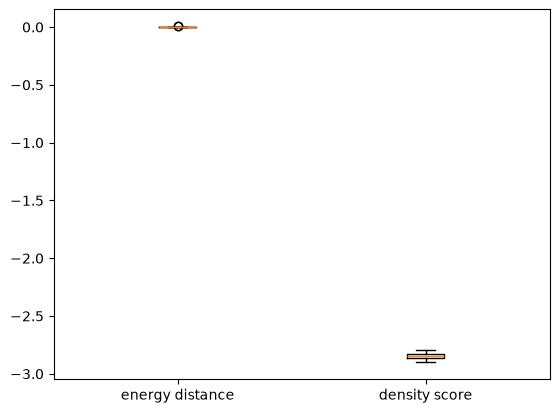

In [10]:
plt.boxplot(res, tick_labels=['energy distance', 'density score'])
plt.show()

In [11]:
n = 2000
U = torch.rand(n, 2)
X = torch.distributions.Normal(0, 1).icdf(U)
mg = MissingnessGenerator(U)
M = mg.example2(U[:,0], U[:, 1])
gmm = GaussianMixtureMAR(kk)
gmm.fit(X, M)

In [12]:
Xtilde = gmm.sample(n)[0]

In [13]:
from scipy.stats import norm
x = np.linspace(-4, 4, 500)

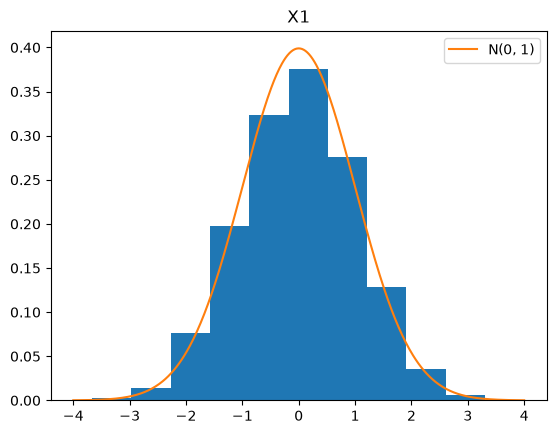

In [14]:
plt.hist(Xtilde[:,0], density=True)
plt.title('X1')
plt.plot(x, norm.pdf(x), label="N(0, 1)")
plt.legend()
plt.show()

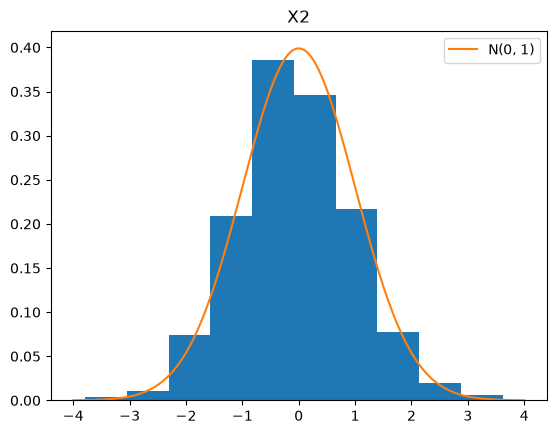

In [15]:
plt.hist(Xtilde[:,1], density=True)
plt.title('X2')
plt.plot(x, norm.pdf(x), label="N(0, 1)")
plt.legend()
plt.show()